 d) Toista analyysi kirjan mukana toimitettavalle synteettiselle tiedostolle signal_to_be_cleaned.csv. Käytä näytteenottoväliä 1 s. Tunnista kolme hallitsevaa positiivista taajuutta ja piirrä puhdistettu signaali.

 Toteutusesimerkki · CSV-aineiston lukeminen. Tiedostossa on sarakkeet time_s ja signal, pilkkuerotin ja desimaalipiste. 
 Se on tätä kirjaa varten muodostettu harjoitusaineisto. Lue se esimerkiksi komennolla 
 data = np.genfromtxt("koodi/data/signal_to_be_cleaned.csv", delimiter=",", names=True).


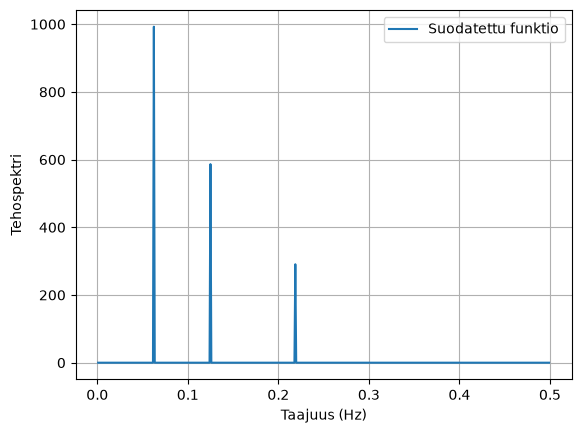

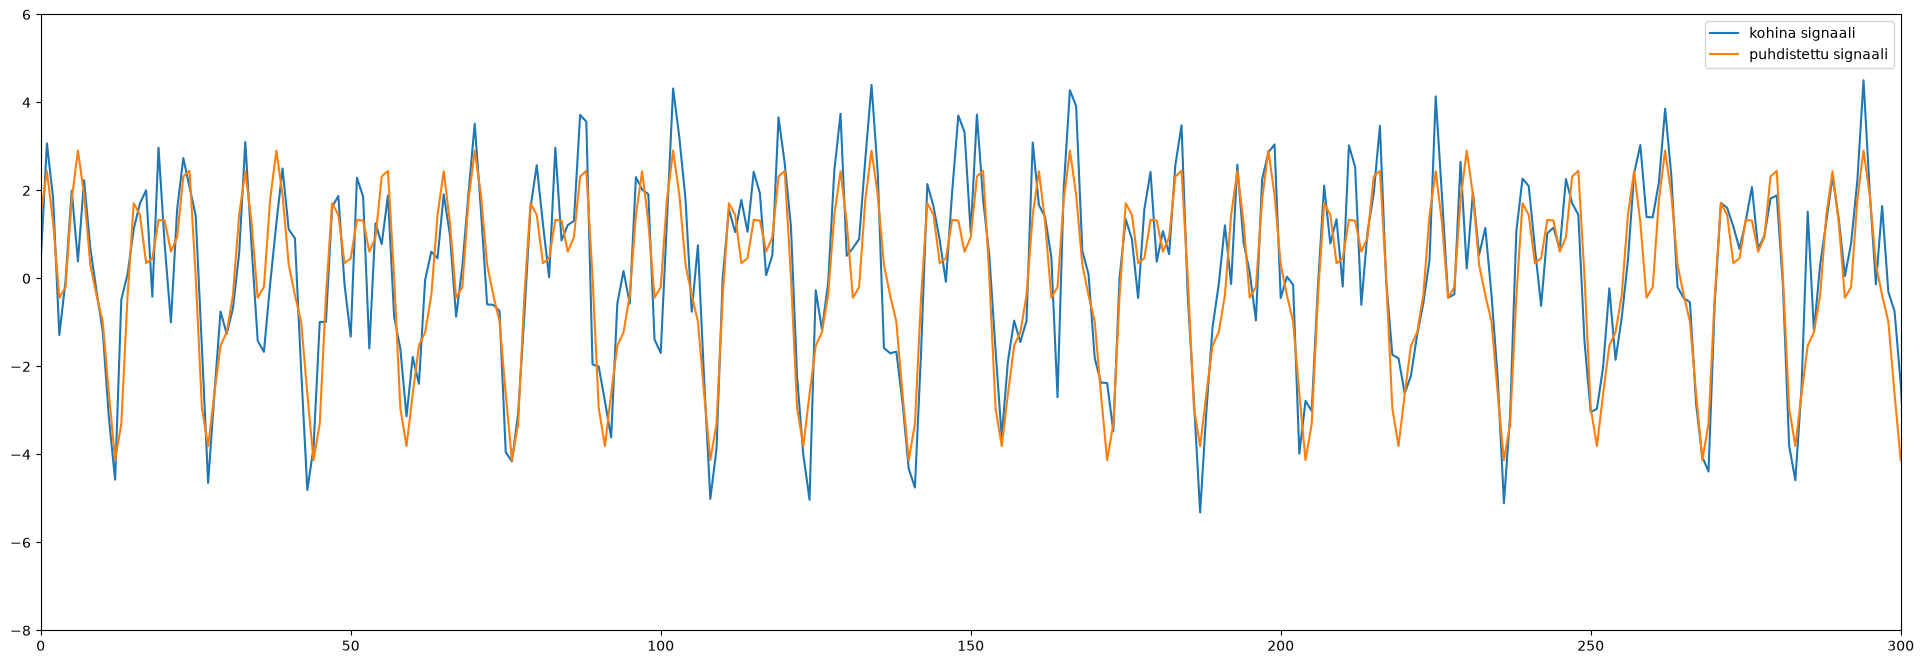

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

#data = pd.read_csv('.\Data\signal_to_be_cleaned-14d273d82595a67c551791ed0806c4a9.csv')

data = np.genfromtxt("./Data/signal_to_be_cleaned.csv", delimiter=",", names=True)
time = data["time_s"]
noisy_signal = data["signal"]

t = time
f = noisy_signal

N = len(f)                          # Näytteiden lukumäärä
dt = (t[-1] - t[0]) / (N - 1)      # Keskimääräinen näytteenottoväli (s)

fourier = np.fft.fft(f)             # Käyttää automaattisesti kaikki N näytettä
freq = np.fft.fftfreq(N, d=dt)      # Taajuusakseli (Hz)
psd = np.abs(fourier)**2 / N

fourier_dom = fourier.copy()
fourier_dom[psd<250] = 0
psd_dom = np.abs(fourier_dom)**2 / N

L = np.arange(1, np.floor(N/2), dtype='int') #Määritellään ne tehospektrin arvot, joita käytetään
PSD = np.array([freq[L], psd_dom[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD[0,:], PSD[1,:], label="Suodatettu funktio")
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
#plt.axhline(50, color="red", linestyle="--", label="Suodatusraja")
plt.legend()
plt.grid()
plt.show()


#palautetaam signaali, jossa mukana ainoastaan dominoivat taajuudet
signal_dom = np.fft.ifft(fourier_dom).real
#plt.axhline(150, color="red", linestyle="--", label="Suodatusraja")

plt.figure(figsize=(16,8))
plt.plot(t,noisy_signal, label="kohina signaali")
plt.plot(t,signal_dom, label="puhdistettu signaali")
plt.axis([0,300,-8,6])
plt.legend()
plt.show()

